# Clasificación de imágenes con CIFAR-10: red densa vs. red convolucional
**Minería de Datos I — ISTEA (Clase 12)** · Prof. Kevin Kovacs

**Objetivo:** comparar una red neuronal de capas densas con una red convolucional (CNN) para clasificar imágenes.
**Datos:** CIFAR-10 (60.000 imágenes de 10 clases), incluido en Keras.
**Qué hice:** antes de mirar los resultados planteé qué clases esperaba que se confundieran, entrené los dos modelos y comparé sus matrices de confusión.
**Resultado principal:** la red densa acierta el 48% en test y la CNN el 69%.
**Qué aprendí:** las capas convolucionales captan patrones de forma y textura que una red densa pierde al aplanar la imagen, y que plantear hipótesis antes de ver los resultados ayuda a interpretarlos.

*Notebook desarrollado durante la cursada de Minería de Datos I (ISTEA).*

> **Consigna (cátedra):** Ejercicio 2. CIFAR10. Este conjunto de datos posee imágenes de 10 clases de la vida cotidiana como
diferentes animales y vehículos.

# a) Carga de datos

In [ ]:
from keras.datasets import cifar10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()


  1048576/170498071 ━━━━━━━━━━━━━━━━━━━━ 48:54 17us/step

# b)


Para visualizar las imágenes, también puede utilizar la función *plt.imshow()*, pero ahora debe tener en
cuenta la dimensión extra:
plt.imshow(x_train[0,:,:,:]) #se incluye la dimensión de canales

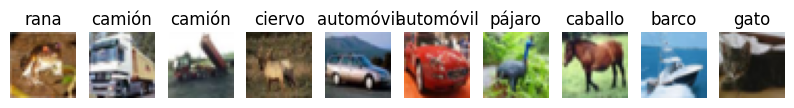

In [ ]:
import matplotlib.pyplot as plt

# Mostramos 10 imagenes con sus respectivas etiquetas
# Nombres de las clases de CIFAR-10
class_names = ['avión', 'automóvil', 'pájaro', 'gato', 'ciervo', 'perro', 'rana', 'caballo', 'barco', 'camión']

# Mostrar las primeras 10 imágenes con su clase
plt.figure(figsize=(10,2))
for i in range(10):
    plt.subplot(1, 10, i+1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis('off')
plt.show()


# c) Aplanamiento

Las imágenes de CIFAR10 son a color, por ende las dimensiones de x_train y x_test son del tipo (N,H,W,C),
donde C es la cantidad de canales (3 para imágenes a color). En el caso de CIFAR10, las imágenes son de
tamaño 32x32, por ende el shape de estos vectores es (N,32,32,3). En este caso también tenemos que
utilizar la capa Flatten al principio del modelo, pero ahora con el nuevo tamaño de entrada:
*model.add(Flatten(input_shape=(32,32,3)))*

In [ ]:
from keras.models import Sequential
from keras.utils import to_categorical
from keras.layers import Input, Flatten, Dense

# Convertir etiquetas a one-hot encoding
y_train_cat = to_categorical(y_train, num_classes=10)
y_test_cat = to_categorical(y_test, num_classes=10)

# Crear el modelo
model = Sequential()

# Aplanar la imagen de entrada
model.add(Input(shape=(32, 32, 3)))
model.add(Flatten())




# d) Modelo



Entrenamiento de un modelo con capas densas (no convolucional)

en este punto vamos a entrenar un modelo simple para clasificar las imágenes del dataset utilizando solamente capas densas (fully connected), sin convoluciones.

Primero normalizamos los valores de los píxeles dividiendo por 255 para que estén entre 0 y 1. Luego, convertimos las etiquetas a formato one-hot para poder usar la función de pérdida de entropía cruzada categórica.

El modelo tiene una capa de entrada que aplana las imágenes de 32x32x3 en vectores de 3072 elementos, seguida por dos capas ocultas densas con funciones de activación ReLU, y una capa de salida con activación softmax que predice la probabilidad para cada una de las 10 clases del dataset.

Después de entrenar, vamos a evaluar la precisión del modelo tanto en el conjunto de entrenamiento como en el de test, y también vamos a generar una matriz de confusión para analizar en qué clases se equivoca más el modelo.

In [ ]:
import numpy as np
from keras.models import Sequential
from keras.layers import Flatten, Dense
from keras.utils import to_categorical
from keras.optimizers import Adam
from sklearn.metrics import confusion_matrix, classification_report

# Normalizamos los valores de las imágenes
x_train_norm = x_train / 255.0
x_test_norm = x_test / 255.0

# Convertimos las etiquetas a one-hot
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

# Definimos el modelo (NO convolucional)
model = Sequential()
model.add(Flatten(input_shape=(32, 32, 3)))  # Aplanar imagen
model.add(Dense(128, activation='relu'))     # Capa oculta
model.add(Dense(64, activation='relu'))      # Otra capa oculta
model.add(Dense(10, activation='softmax'))   # Capa de salida

# Compilamos
model.compile(optimizer=Adam(),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Entrenamos
history = model.fit(x_train_norm, y_train_cat,
                    epochs=10, batch_size=64,
                    validation_data=(x_test_norm, y_test_cat))


/usr/local/lib/python3.11/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.2750 - loss: 1.9999 - val_accuracy: 0.3689 - val_loss: 1.7668
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.3768 - loss: 1.7355 - val_accuracy: 0.3964 - val_loss: 1.6811
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.4105 - loss: 1.6518 - val_accuracy: 0.4196 - val_loss: 1.6351
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.4282 - loss: 1.5965 - val_accuracy: 0.4325 - val_loss: 1.5969
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.4473 - loss: 1.5548 - val_accuracy: 0.4343 - val_loss: 1.5742
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.4507 - loss: 1.5401 - val_accuracy: 0.4563 - val_loss: 1.5199
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.4642 - loss: 1.4943 - val_accuracy: 0.4418 - val_loss: 1.5472
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.4739 - loss: 1.4772 - val_ac

evaluamos:

In [ ]:
# Evaluación en test
test_loss, test_accuracy = model.evaluate(x_test_norm, y_test_cat, verbose=0)
train_loss, train_accuracy = model.evaluate(x_train_norm, y_train_cat, verbose=0)

print(f"Accuracy de entrenamiento: {train_accuracy:.2f}")
print(f"Accuracy de test: {test_accuracy:.2f}")


Accuracy de entrenamiento: 0.50
Accuracy de test: 0.48


Antes de observar la matriz de confusión, estimo que algunas clases que probablemente se confundan entre sí son:

"gato" y "perro", por ser animales domésticos con formas similares en imágenes pequeñas.

"camión" y "automóvil", por compartir características visuales (ruedas, forma rectangular).

"barco" y "avión", ya que en algunas imágenes pueden aparecer en ambientes parecidos o con formas difíciles de distinguir sin contexto.

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


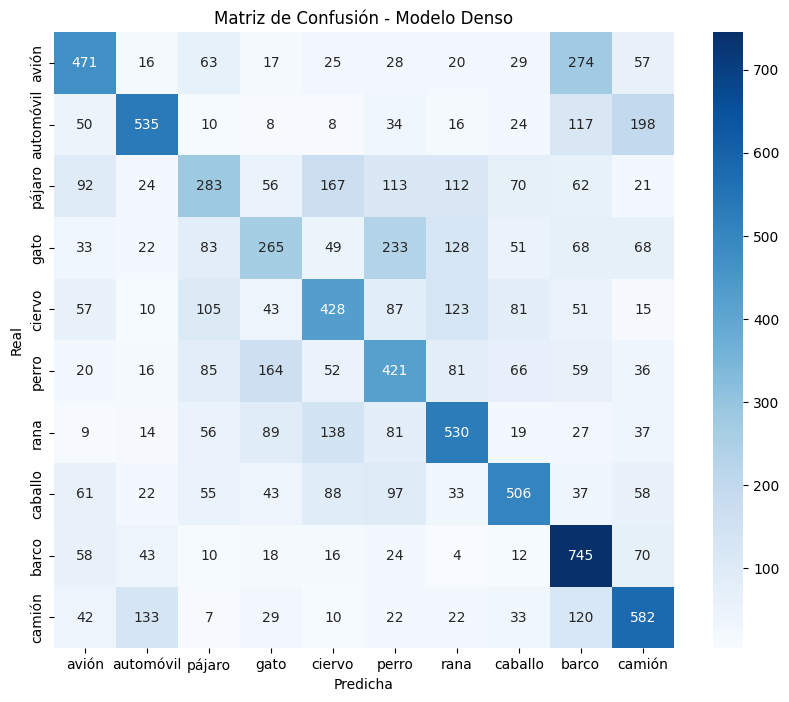

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Predicciones
y_pred_probs = model.predict(x_test_norm)
y_pred = np.argmax(y_pred_probs, axis=1)

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicha")
plt.ylabel("Real")
plt.title("Matriz de Confusión - Modelo Denso")
plt.show()


In [ ]:
cm

array([[471,  16,  63,  17,  25,  28,  20,  29, 274,  57],
       [ 50, 535,  10,   8,   8,  34,  16,  24, 117, 198],
       [ 92,  24, 283,  56, 167, 113, 112,  70,  62,  21],
       [ 33,  22,  83, 265,  49, 233, 128,  51,  68,  68],
       [ 57,  10, 105,  43, 428,  87, 123,  81,  51,  15],
       [ 20,  16,  85, 164,  52, 421,  81,  66,  59,  36],
       [  9,  14,  56,  89, 138,  81, 530,  19,  27,  37],
       [ 61,  22,  55,  43,  88,  97,  33, 506,  37,  58],
       [ 58,  43,  10,  18,  16,  24,   4,  12, 745,  70],
       [ 42, 133,   7,  29,  10,  22,  22,  33, 120, 582]])

Al observar la matriz de confusión, se confirman varias de las hipótesis planteadas previamente:

"Gato" (clase 3) y "perro" (clase 5): se confunden con frecuencia. Por ejemplo, hay 233 imágenes de “gato” clasificadas como “perro” y 164 de “perro” clasificadas como “gato”.

"Camión" (clase 9) y "automóvil" (clase 1): también muestran confusiones importantes. Hay 198 imágenes de “automóvil” clasificadas como “camión”, y 133 de “camión” clasificadas como “automóvil”.

"Avión" (clase 0) y "barco" (clase 8): hay 274 imágenes de “avión” clasificadas como “barco”, lo que indica una confusión significativa.

Esto refleja que un modelo simple, sin capas convolucionales, tiene dificultad para captar patrones espaciales y de textura necesarios para diferenciar visualmente entre clases similares. Estos errores son esperables y justifican la necesidad de modelos más complejos como las redes convolucionales (CNN).

# e) CNN

In [ ]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from keras.utils import to_categorical
from keras.optimizers import Adam
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Convertimos las etiquetas a one-hot encoding
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

# Normalizamos los valores de píxeles (entre 0 y 1)
x_train_norm = x_train.astype('float32') / 255.0
x_test_norm = x_test.astype('float32') / 255.0

# Creamos el modelo CNN
model_cnn = Sequential()

# Primera capa convolucional
model_cnn.add(Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model_cnn.add(MaxPooling2D(pool_size=(2, 2)))

# Segunda capa convolucional
model_cnn.add(Conv2D(64, (3, 3), activation='relu'))
model_cnn.add(MaxPooling2D(pool_size=(2, 2)))

# Aplanamiento
model_cnn.add(Flatten())

# Capa densa
model_cnn.add(Dense(64, activation='relu'))

# Capa de salida
model_cnn.add(Dense(10, activation='softmax'))

# Compilamos el modelo
model_cnn.compile(optimizer=Adam(), loss='categorical_crossentropy', metrics=['accuracy'])

# Entrenamiento
history_cnn = model_cnn.fit(x_train_norm, y_train_cat, epochs=10, batch_size=64, validation_split=0.2)

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 58s 90ms/step - accuracy: 0.3622 - loss: 1.7485 - val_accuracy: 0.5354 - val_loss: 1.3123
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 52s 83ms/step - accuracy: 0.5655 - loss: 1.2383 - val_accuracy: 0.5881 - val_loss: 1.1586
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 83ms/step - accuracy: 0.6234 - loss: 1.0749 - val_accuracy: 0.6158 - val_loss: 1.0874
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 81s 81ms/step - accuracy: 0.6677 - loss: 0.9597 - val_accuracy: 0.6544 - val_loss: 0.9876
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 55s 88ms/step - accuracy: 0.6917 - loss: 0.8851 - val_accuracy: 0.6614 - val_loss: 0.9791
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 78s 81ms/step - accuracy: 0.7203 - loss: 0.8108 - val_accuracy: 0.6656 - val_loss: 0.9672
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 51s 81ms/step - accuracy: 0.7361 - loss: 0.7551 - val_accuracy: 0.6897 - val_loss: 0.9081
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 84s 84ms/step - accuracy: 0.7550 - loss: 0.7023 - 

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.6864 - loss: 0.9370
Accuracy en test del modelo convolucional: 0.6855
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step


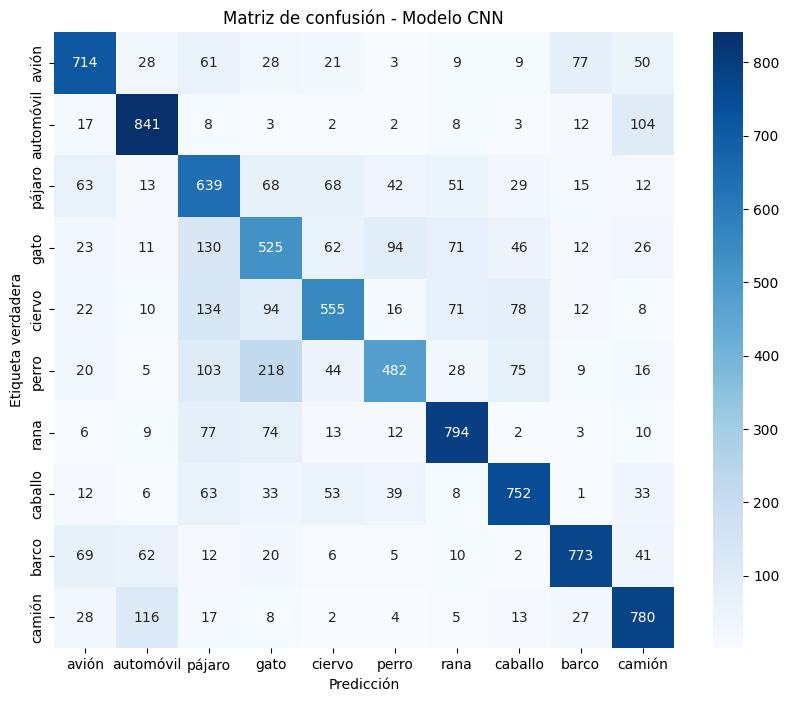

In [ ]:
# Evaluamos en el set de test
test_loss_cnn, test_accuracy_cnn = model_cnn.evaluate(x_test_norm, y_test_cat)
print(f"Accuracy en test del modelo convolucional: {test_accuracy_cnn:.4f}")

# Predicciones
y_pred_cnn = model_cnn.predict(x_test_norm)
y_pred_labels_cnn = np.argmax(y_pred_cnn, axis=1)
y_true_labels = y_test.flatten()

# Matriz de confusión
cm_cnn = confusion_matrix(y_true_labels, y_pred_labels_cnn)

# Visualizamos la matriz
plt.figure(figsize=(10,8))
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Predicción')
plt.ylabel('Etiqueta verdadera')
plt.title('Matriz de confusión - Modelo CNN')
plt.show()


In [ ]:
cm_cnn

array([[714,  28,  61,  28,  21,   3,   9,   9,  77,  50],
       [ 17, 841,   8,   3,   2,   2,   8,   3,  12, 104],
       [ 63,  13, 639,  68,  68,  42,  51,  29,  15,  12],
       [ 23,  11, 130, 525,  62,  94,  71,  46,  12,  26],
       [ 22,  10, 134,  94, 555,  16,  71,  78,  12,   8],
       [ 20,   5, 103, 218,  44, 482,  28,  75,   9,  16],
       [  6,   9,  77,  74,  13,  12, 794,   2,   3,  10],
       [ 12,   6,  63,  33,  53,  39,   8, 752,   1,  33],
       [ 69,  62,  12,  20,   6,   5,  10,   2, 773,  41],
       [ 28, 116,  17,   8,   2,   4,   5,  13,  27, 780]])

Después de entrenar y evaluar un modelo convolucional simple, se observa una mejora clara respecto del modelo con capas densas: el accuracy en test pasa de 48% a 69% y la matriz de confusión queda mucho más concentrada en la diagonal.

Algunos ejemplos:

- **Automóvil** (clase 1) pasa de 535 a 841 aciertos, y su confusión con **camión** baja de 198 a 104 imágenes.
- **Rana** (clase 6) pasa de 530 a 794 aciertos.
- Los **aviones** clasificados como **barco** bajan de 274 a 77.
- **Gato y perro** siguen siendo el par más difícil: los gatos clasificados como perro bajan de 233 a 94, pero los perros clasificados como gato suben de 164 a 218.

Esto muestra que las redes convolucionales funcionan mejor para clasificar imágenes.

## Conclusiones
- La red con capas densas llega a un 48% de accuracy en test; la CNN, a un 69%. Como hay 10 clases, adivinar al azar daría un 10%.
- Las hipótesis planteadas antes de ver la matriz de confusión se confirmaron: gato/perro, automóvil/camión y avión/barco son los pares que más se confunden.
- La CNN reduce mucho esas confusiones, salvo entre gato y perro, que sigue siendo el par más difícil.
- Mejoras posibles: más capas convolucionales, *dropout* para reducir el sobreajuste y aumento de datos (rotar o espejar imágenes).